# CivicFlux — Intervention Outcomes Research

**Notebook 09 · synthetic outcome-data experiment · predictive association only**

No verified municipal intervention outcomes or approval workflow is present in the inspected repository. This notebook creates an explicitly synthetic schema and experiment so data handling and evaluation can be demonstrated. It does not report real intervention success or causal benefits.

## 01. Objective and label integrity

Research design: predict independently verified completion success and resolution time from **pre-intervention** planned conditions in a synthetic dataset. An approved or completed work order is not automatically a success. A valid success label requires completion, named independent verifier, verification timestamp and evidence reference.

Synthetic labels are generated by a declared mechanism with resource allocation associated with initial severity. This induces selection bias. Forecasting labels in this toy population does not tell us what would have happened under a different intervention; predictive association is not a treatment effect.

### 1.1 Setup

Use versioned CivicFlux schema and inference helpers.

In [1]:
from pathlib import Path
import sys,json,platform,importlib.metadata
import numpy as np,pandas as pd,seaborn as sns,matplotlib.pyplot as plt
from IPython.display import display
import joblib
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.civicflux.outcomes import (VERSION,REQUIRED,FEATURES,OutcomeBundle,generate_synthetic_outcomes,
 validate_outcome_record,verify_outcome,leakage_safe_features)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression,Ridge
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit,RandomizedSearchCV,cross_validate
from sklearn.metrics import (average_precision_score,roc_auc_score,brier_score_loss,precision_score,recall_score,f1_score,
 mean_absolute_error,mean_squared_error,classification_report,ConfusionMatrixDisplay,PrecisionRecallDisplay)
from sklearn.calibration import calibration_curve
from scipy.stats import loguniform
sns.set_theme(style='whitegrid');SEED=42
OUT=ROOT/'artifacts'/'intervention_outcomes'/'v1.1.0';OUT.mkdir(parents=True,exist_ok=True)
print(platform.python_version(),{p:importlib.metadata.version(p) for p in ['pandas','numpy','scikit-learn']})

3.13.5 {'pandas': '2.2.3', 'numpy': '2.3.5', 'scikit-learn': '1.6.1'}


### 1.2 Existing backend audit

No intervention records, verification service, resource optimizer or civic approval endpoint is present in the reviewed project. Existing SAGE components refer to synthetic electronics burn-in; they are excluded.

In [2]:
print('Outcome fields are generated in src/civicflux/outcomes.py')
print('No verified real intervention outcomes discovered in available project datasets.')
print('Existing unrelated backend approvals are not relabeled as CivicFlux municipal interventions.')

Outcome fields are generated in src/civicflux/outcomes.py
No verified real intervention outcomes discovered in available project datasets.
Existing unrelated backend approvals are not relabeled as CivicFlux municipal interventions.


## 02. Outcome schema and synthetic data provenance

The schema distinguishes proposal, approval, progress, completion and independent outcome verification. In this experiment every record is tagged `source_type=synthetic`. The seed and label mechanism are fixed and exported. The generated row count is a pedagogical sample size, not an observed civic record count.

### 2.1 Define all fields

Feature candidates are known at assignment time. Completion, verification evidence and resolution fields are post-assignment outcomes and never model inputs.

In [3]:
print('Required schema:',REQUIRED)
print('Pre-assignment features:',FEATURES)
data=generate_synthetic_outcomes(n=6000,seed=SEED)
assert data.source_type.eq('synthetic').all()
assert set(FEATURES).isdisjoint({'status','completion_time','outcome_status','verified_success','verification_time','resolution_hours'})
display(data.head());display(data.dtypes.to_frame('dtype'))
(OUT/'synthetic_intervention_records.csv').write_text(data.to_csv(index=False))

Required schema: ['incident_id', 'intervention_id', 'intervention_type', 'initial_severity', 'planned_crew_type', 'planned_crew_count', 'planned_pump_count', 'planned_cost', 'risk_score_at_assignment', 'assignment_time', 'completion_time', 'status', 'outcome_status', 'verified_success', 'verified_by', 'verification_time', 'resolution_hours', 'evidence_ref', 'source_type']
Pre-assignment features: ['intervention_type', 'initial_severity', 'planned_crew_type', 'planned_crew_count', 'planned_pump_count', 'planned_cost', 'risk_score_at_assignment']


,incident_id,intervention_id,intervention_type,initial_severity,planned_crew_type,planned_crew_count,planned_pump_count,planned_cost,risk_score_at_assignment,assignment_time,...,verified_success,verified_by,verification_time,resolution_hours,evidence_ref,source_type,event_group,underlying_simulated_success,latent_success_probability,expected_cost_assumption
0,SYN-I-000000,SYN-A-000000,drain_clear,4,drain,3,0,6100,0.773438,2019-07-10 11:00:00,...,1.0,independent_simulated_auditor,2019-07-11 06:59:50.492208955,15.997359,synthetic-simulation-record,synthetic,SYN-G-000000,1,0.562177,6100
1,SYN-I-000001,SYN-A-000001,drain_clear,5,drain,3,0,6800,0.754620,2023-01-02 04:00:00,...,NaN,None,NaT,27.210421,None,synthetic,SYN-G-000001,1,0.450166,6800
2,SYN-I-000002,SYN-A-000002,pipe_repair,1,water,2,0,2700,0.211400,2024-03-16 20:00:00,...,1.0,independent_simulated_auditor,2024-03-18 22:47:19.304458317,8.788696,synthetic-simulation-record,synthetic,SYN-G-000002,1,0.750260,2700
3,SYN-I-000003,SYN-A-000003,drain_clear,2,drain,2,0,3200,0.343429,2023-07-18 08:00:00,...,NaN,None,NaT,NaN,None,synthetic,SYN-G-000003,1,0.622459,3200
4,SYN-I-000004,SYN-A-000004,pump_repair,1,water,2,1,3800,0.141683,2020-02-13 01:00:00,...,1.0,independent_simulated_auditor,2020-02-14 11:59:26.734756254,13.990760,synthetic-simulation-record,synthetic,SYN-G-000004,1,0.622459,3800


,dtype
incident_id,object
intervention_id,object
intervention_type,object
initial_severity,int64
planned_crew_type,object
planned_crew_count,int64
planned_pump_count,int64
planned_cost,int64
risk_score_at_assignment,float64
assignment_time,datetime64[ns]


1611645

### 2.2 Provenance and assumptions

Generated records have synthetic identifiers, hypothetical severity/resource distributions, simulated outcomes and dates. None encodes a real municipal incident.

In [4]:
manifest={'component':'intervention_outcome_research','version':VERSION,'synthetic':True,'seed':SEED,'n':len(data),
 'period':[str(data.assignment_time.min()),str(data.assignment_time.max())],
 'completion_rate':float(data.status.eq('completed').mean()),'verification_rate':float(data.outcome_status.str.startswith('verified_').mean()),
 'success_mechanism':'simulated logistic response to severity/intervention/resource choices; assignment is confounded',
 'causal_claim':None,'limitations':['No observed interventions','No real outcome verification','No counterfactual outcomes','Selection bias is built into simulation']}
(OUT/'synthetic_data_manifest.json').write_text(json.dumps(manifest,indent=2))
print(json.dumps(manifest,indent=2))

{
  "component": "intervention_outcome_research",
  "version": "1.0.0",
  "synthetic": true,
  "seed": 42,
  "n": 6000,
  "period": [
    "2019-01-01 00:00:00",
    "2024-12-31 17:00:00"
  ],
  "completion_rate": 0.938,
  "verification_rate": 0.5896666666666667,
  "success_mechanism": "simulated logistic response to severity/intervention/resource choices; assignment is confounded",
  "causal_claim": null,
  "limitations": [
    "No observed interventions",
    "No real outcome verification",
    "No counterfactual outcomes",
    "Selection bias is built into simulation"
  ]
}


## 03. Inspection and EDA

Describe completion and verification separately. Resolution time is available only for completed jobs in this generator; verified success is available only for independently verified completed records. Missing outcomes remain missing. Never code an unverified row as success=0.

### 3.1 Coverage, missing values and status

A verified outcome subset can be selected for classification. Completion alone does not create an outcome label.

,missing,missing_percent
incident_id,0,0.000000
intervention_id,0,0.000000
intervention_type,0,0.000000
initial_severity,0,0.000000
planned_crew_type,0,0.000000
planned_crew_count,0,0.000000
planned_pump_count,0,0.000000
planned_cost,0,0.000000
risk_score_at_assignment,0,0.000000
assignment_time,0,0.000000


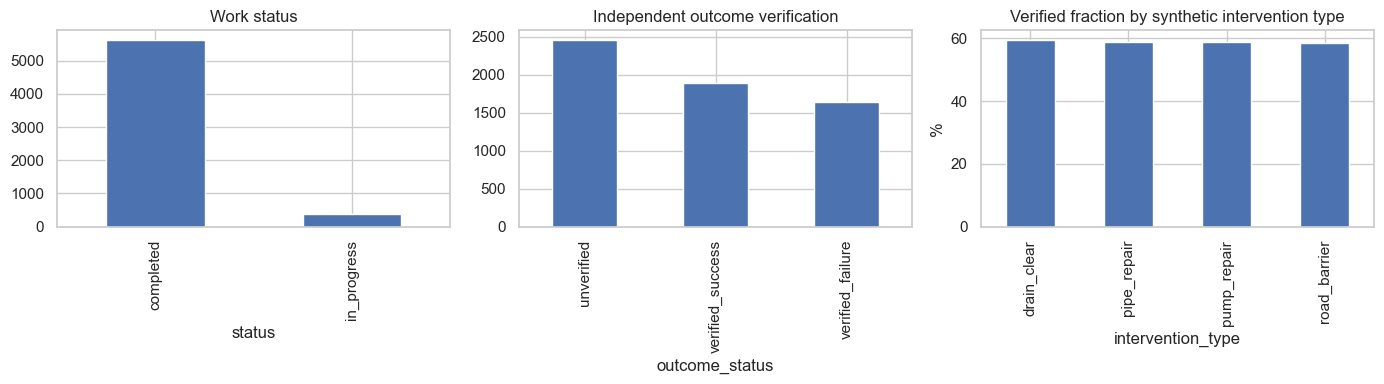

In [5]:
quality=pd.DataFrame({'missing':data.isna().sum(),'missing_percent':100*data.isna().mean()})
display(quality)
fig,ax=plt.subplots(1,3,figsize=(14,4))
data.status.value_counts().plot.bar(ax=ax[0],title='Work status')
data.outcome_status.value_counts().plot.bar(ax=ax[1],title='Independent outcome verification')
(100*data.outcome_status.str.startswith('verified_').groupby(data.intervention_type).mean()).plot.bar(ax=ax[2],title='Verified fraction by synthetic intervention type',ylabel='%')
plt.tight_layout();plt.show()

### 3.2 Intervention type and severity

Outcomes differ by type only because the synthetic generator assigns differing inputs and mechanisms.

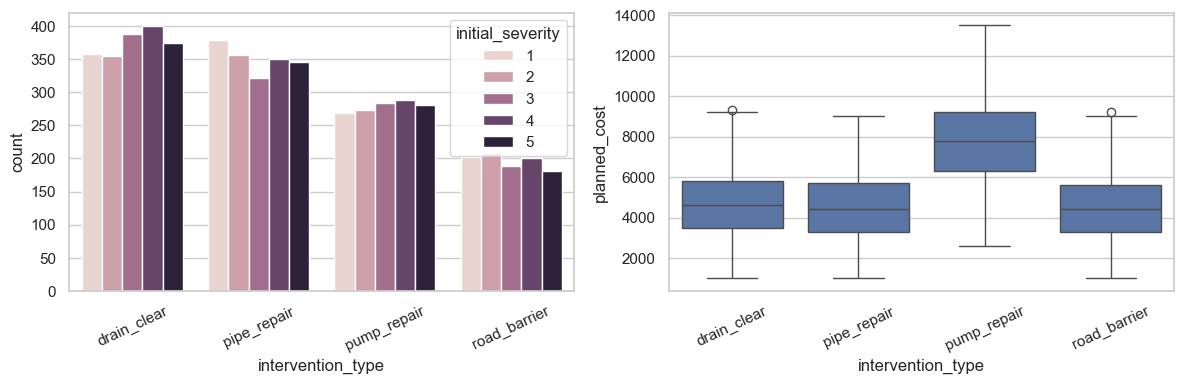

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=data,x='intervention_type',hue='initial_severity',ax=ax[0]);ax[0].tick_params(axis='x',rotation=25)
sns.boxplot(data=data,x='intervention_type',y='planned_cost',ax=ax[1]);ax[1].tick_params(axis='x',rotation=25)
plt.tight_layout();plt.show()

### 3.3 Completion, verification delay and resolution

Verification delay is defined only for verified rows and is not a predictor.

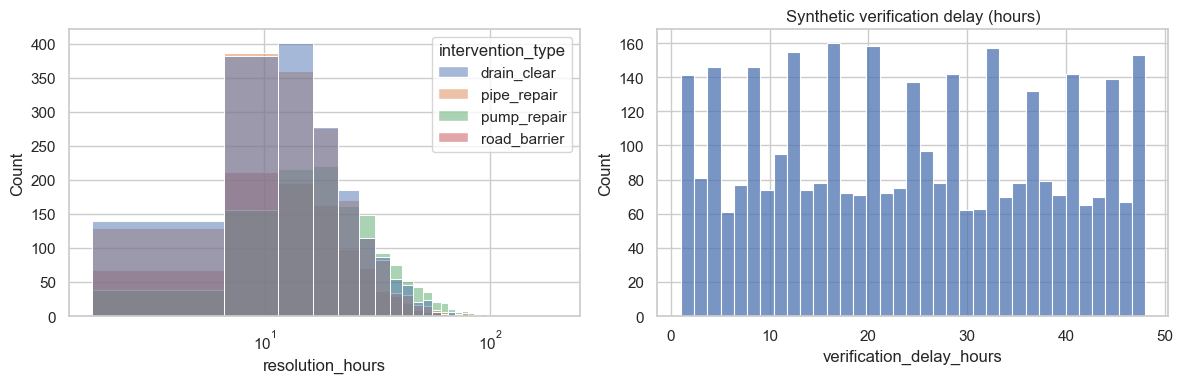

In [7]:
verified=data[data.outcome_status.str.startswith('verified_')].copy()
verified['verification_delay_hours']=(pd.to_datetime(verified.verification_time)-pd.to_datetime(verified.completion_time)).dt.total_seconds()/3600
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=data[data.status.eq('completed')],x='resolution_hours',hue='intervention_type',bins=40,ax=ax[0]);ax[0].set_xscale('log')
sns.histplot(verified,x='verification_delay_hours',bins=35,ax=ax[1]);ax[1].set_title('Synthetic verification delay (hours)')
plt.tight_layout();plt.show()

### 3.4 Seasonal assignment patterns

Chronological shift is important even for generated records.

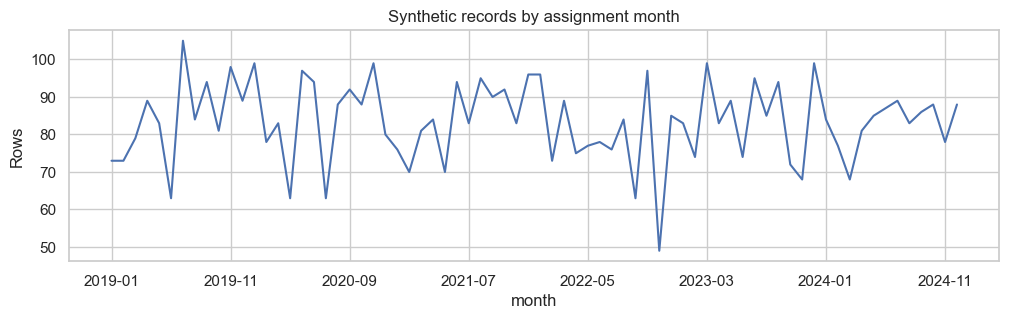

In [8]:
monthly=data.assign(month=pd.to_datetime(data.assignment_time).dt.to_period('M').astype(str)).groupby('month').agg(rows=('incident_id','size'),verified=('outcome_status',lambda x:x.str.startswith('verified_').mean()))
monthly.rows.plot(title='Synthetic records by assignment month',ylabel='Rows',figsize=(12,3));plt.show()

### 3.5 Planned resource and outcome associations

These are descriptive associations inside a biased simulation, not benefits caused by using more resources.

,n,success,severity,crew,pumps
intervention_type,,,,,
drain_clear,1116,0.579749,3.043907,2.416667,0.000000
pipe_repair,1031,0.602328,2.993210,2.402522,0.000000
pump_repair,819,0.417582,3.036630,2.406593,1.500611
road_barrier,572,0.496503,2.989510,2.391608,0.000000


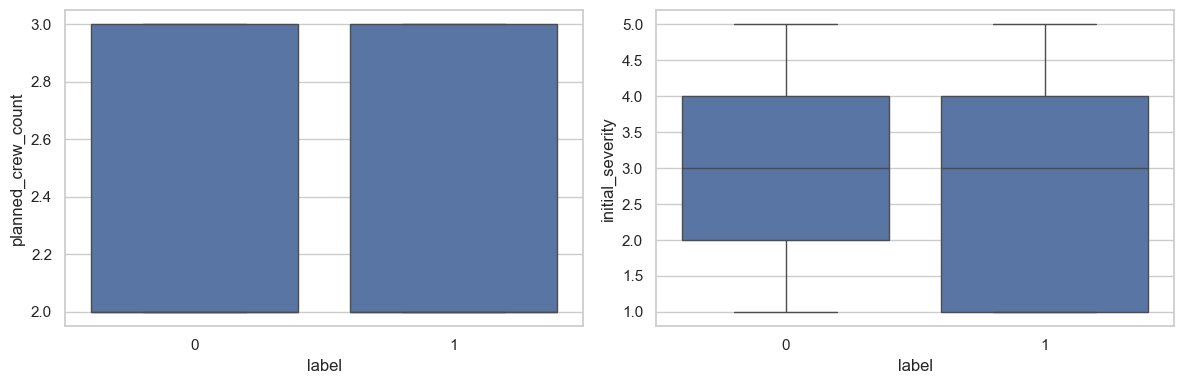

In [9]:
valid=data[data.outcome_status.isin(['verified_success','verified_failure'])].copy();valid['label']=valid.verified_success.astype(int)
display(valid.groupby('intervention_type').agg(n=('label','size'),success=('label','mean'),severity=('initial_severity','mean'),crew=('planned_crew_count','mean'),pumps=('planned_pump_count','mean')))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=valid,x='label',y='planned_crew_count',ax=ax[0]);sns.boxplot(data=valid,x='label',y='initial_severity',ax=ax[1]);plt.tight_layout();plt.show()

## 04. Preprocessing and leakage review

Parse timestamps explicitly, enforce verification rules, preserve missing outcomes and remove any row with contradictory completed/verification state. Train/test split is by assignment chronology. Classification uses only independently verified records; regression uses completed records whose resolution time is observed. Planned resources can reflect policy decisions and are predictive associations only.

### 4.1 Validate record states

Validate a representative complete record and demonstrate that a completed-but-unverified item has no supervised success label.

In [10]:
example=data.iloc[0].to_dict();validated=validate_outcome_record(example)
display(pd.Series({k:validated[k] for k in ['status','outcome_status','verified_success','verified_by','evidence_ref','source_type']}))
assert not data.loc[~data.outcome_status.str.startswith('verified_'),'verified_success'].notna().any()

status                                  completed
outcome_status                   verified_success
verified_success                              1.0
verified_by         independent_simulated_auditor
evidence_ref          synthetic-simulation-record
source_type                             synthetic
dtype: object

### 4.2 Leakage audit

Feature allowlist is fixed in the shared inference implementation. Outcome, completion time, verifier, evidence and resolution duration are forbidden predictors.

In [11]:
assert set(leakage_safe_features(data).columns)==set(FEATURES)
forbidden={'incident_id','intervention_id','completion_time','outcome_status','verified_success','verified_by','verification_time','evidence_ref','resolution_hours','status'}
assert set(FEATURES).isdisjoint(forbidden)
print('PASS. Prediction fields available at assignment:',FEATURES)

PASS. Prediction fields available at assignment: ['intervention_type', 'initial_severity', 'planned_crew_type', 'planned_crew_count', 'planned_pump_count', 'planned_cost', 'risk_score_at_assignment']


### 4.3 Train-only preprocessing

One-hot categories and numeric scaling/imputation are fit inside each pipeline and refit within chronological CV.

In [12]:
cat=['intervention_type','planned_crew_type'];num=[c for c in FEATURES if c not in cat]
def preprocess(scale=False):
    nums=[('numeric',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True),num)]
    if scale:nums=[('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('scale',StandardScaler())]),num)]
    return ColumnTransformer(nums+[('categorical',OneHotEncoder(handle_unknown='ignore'),cat)])
def classification_pipeline(estimator,scale=False):return Pipeline([('preprocess',preprocess(scale)),('model',estimator)])

## 05. Time-aware prediction strategy

Use the first 60% of assignment dates for development, the next 20% for validation/threshold selection, and the last 20% as a final time holdout. All generated records have unique synthetic event IDs; each event is kept wholly within one time block. Three expanding CV folds evaluate the verified development subset. A target threshold is chosen on validation records only. Test scores never select the model.

### 5.1 Split data and preserve group boundaries

Split on global assignment timestamps before filtering into task-specific cohorts.

In [13]:
data['assignment_time']=pd.to_datetime(data.assignment_time)
times=np.sort(data.assignment_time.unique());cut1,cut2=times[int(.6*len(times))],times[int(.8*len(times))]
data['period']=np.where(data.assignment_time<cut1,'train',np.where(data.assignment_time<cut2,'validation','test'))
assert data.event_group.is_unique
print('Boundaries',cut1,cut2)
display(data.groupby('period').agg(rows=('incident_id','size'),groups=('event_group','nunique'),start=('assignment_time','min'),end=('assignment_time','max')))

Boundaries 2022-07-26T18:00:00.000000000 2023-10-13T21:00:00.000000000


,rows,groups,start,end
period,,,,
test,1200,1200,2023-10-13 21:00:00,2024-12-31 17:00:00
train,3600,3600,2019-01-01 00:00:00,2022-07-26 15:00:00
validation,1200,1200,2022-07-26 18:00:00,2023-10-12 23:00:00


### 5.2 Build verified success cohort

Only completed interventions with independent verification enter classification.

In [14]:
classification=data[data.outcome_status.isin(['verified_success','verified_failure'])].copy()
classification['target']=classification.verified_success.astype(int)
train=classification[classification.period.eq('train')];val=classification[classification.period.eq('validation')];test=classification[classification.period.eq('test')]
for label,part in [('train',train),('validation',val),('test',test)]:print(label,len(part),'verified positives',int(part.target.sum()),'prevalence',part.target.mean())
assert train.target.nunique()==2 and val.target.nunique()==2 and test.target.nunique()==2

train 2149 verified positives 1138 prevalence 0.5295486272684969
validation 705 verified positives 383 prevalence 0.5432624113475177
test 684 verified positives 373 prevalence 0.5453216374269005


### 5.3 TimeSeries CV for verified success

A group cannot cross folds; each event is a unique intervention and groups are assigned before CV.

In [15]:
train=train.sort_values('assignment_time').reset_index(drop=True)
cv=list(TimeSeriesSplit(n_splits=3).split(train))
for tr,va in cv:
    assert train.iloc[tr].assignment_time.max()<train.iloc[va].assignment_time.min()
    assert set(train.iloc[tr].event_group).isdisjoint(set(train.iloc[va].event_group))

## 06. Success model experiments

Compare a prior baseline, Logistic Regression, Random Forest and XGBoost on verified synthetic records. Average precision is the primary ranking metric for potentially imbalanced labels. Report Brier score, ROC-AUC and threshold metrics. The trained predictions are synthetic research surrogates.

### 6.1 Candidate models

Tree candidates do not need scaling; Logistic Regression scales numeric features.

In [16]:
from xgboost import XGBClassifier,XGBRegressor
models={'Prior':classification_pipeline(DummyClassifier(strategy='prior')),
 'Logistic':classification_pipeline(LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),True),
 'Random Forest':classification_pipeline(RandomForestClassifier(n_estimators=120,min_samples_leaf=8,class_weight='balanced',random_state=SEED,n_jobs=2)),
 'XGBoost':classification_pipeline(XGBClassifier(n_estimators=120,max_depth=3,learning_rate=.05,subsample=.85,colsample_bytree=.85,eval_metric='logloss',tree_method='hist',n_jobs=2,random_state=SEED))}
Xtr=train[FEATURES];ytr=train.target;Xv=val[FEATURES];yv=val.target;Xt=test[FEATURES];yt=test.target

### 6.2 Cross-validation comparison

The folds use development data only; no temporal shuffling.

,AP,AP_std,Brier,AUC
model,,,,
Random Forest,0.645494,0.008300,0.240687,0.618273
Logistic,0.643469,0.039224,0.236907,0.633163
XGBoost,0.632341,0.016391,0.240155,0.616505
Prior,0.531347,0.015506,0.249111,0.500000


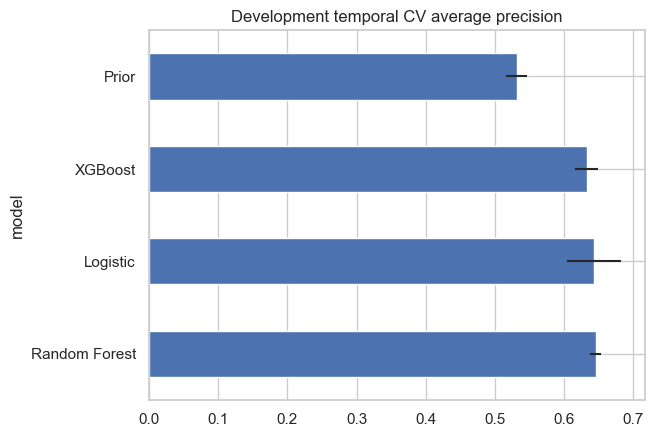

In [17]:
cv_rows=[]
for name,est in models.items():
    scores=cross_validate(est,Xtr,ytr,cv=cv,scoring={'ap':'average_precision','brier':'neg_brier_score','auc':'roc_auc'},error_score='raise')
    for i in range(3):cv_rows.append({'model':name,'fold':i,'AP':scores['test_ap'][i],'Brier':-scores['test_brier'][i],'AUC':scores['test_auc'][i]})
cv_results=pd.DataFrame(cv_rows);cv_summary=cv_results.groupby('model').agg(AP=('AP','mean'),AP_std=('AP','std'),Brier=('Brier','mean'),AUC=('AUC','mean')).sort_values('AP',ascending=False)
display(cv_summary);cv_results.to_csv(OUT/'success_cv.csv',index=False)
cv_summary.AP.plot.barh(xerr=cv_summary.AP_std,title='Development temporal CV average precision');plt.show()

### 6.3 Tune leading learned candidates

A small declared randomized search compares Logistic Regression and XGBoost. Both tune within temporal folds.

In [18]:
spaces={'Logistic':{'model__C':loguniform(.03,30),'model__class_weight':[None,'balanced']},
 'XGBoost':{'model__n_estimators':[80,120,180],'model__max_depth':[2,3,5],'model__learning_rate':[.03,.08,.15],'model__min_child_weight':[1,5,10]}}
searches={};ranking=cv_summary.AP.to_dict()
for name,space in spaces.items():
    search=RandomizedSearchCV(models[name],space,n_iter=5,cv=cv,scoring='average_precision',refit=True,random_state=SEED,n_jobs=1,error_score='raise')
    search.fit(Xtr,ytr);searches[name]=search;ranking[name+' tuned']=search.best_score_
    pd.DataFrame(search.cv_results_).to_csv(OUT/(name+'_success_search.csv'),index=False)
    print(name,search.best_params_,-search.best_score_ if False else search.best_score_)
selected=max(ranking,key=ranking.get)
final=searches[selected.removesuffix(' tuned')].best_estimator_ if selected.endswith(' tuned') else models[selected].fit(Xtr,ytr)
print('CV selection:',selected)

Logistic {'model__C': np.float64(0.652558593563329), 'model__class_weight': None} 0.6437867787759228
XGBoost {'model__n_estimators': 80, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.03} 0.6411659001925599


CV selection: Random Forest


### Validation discrimination threshold

The original F1 search selected an almost-all-positive policy. Balanced accuracy now defines a diagnostic validation threshold. Success estimates remain unsupported for operational decisions regardless of this threshold.

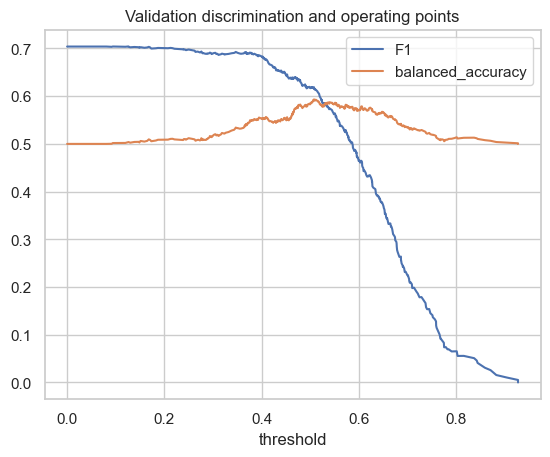

Research diagnostic threshold 0.507379373313727 not an allocation decision


In [19]:
from src.civicflux.review import select_score_threshold
pv=final.predict_proba(Xv)[:,1]
threshold,threshold_review=select_score_threshold(yv,pv,objective='balanced_accuracy')
threshold_review.to_csv(OUT/'success_validation_operating_points.csv',index=False)
threshold_review.plot(x='threshold',y=['F1','balanced_accuracy'],title='Validation discrimination and operating points');plt.show()
print('Research diagnostic threshold',threshold,'not an allocation decision')

## 07. Locked test evaluation for success

Evaluate once on the final period. Report discrimination, precision/recall, calibration, confusion matrix, error slices and leave results intact even if poor. The metrics describe this synthetic, selection-biased data generator.

### 7.1 Final classification metrics

No test label alters the threshold or model selection.

{
  "average_precision": 0.6189174272836088,
  "ROC_AUC": 0.5707869624061447,
  "Brier": 0.2574041833672511,
  "precision": 0.6,
  "recall": 0.5308310991957105,
  "F1": 0.5633001422475107,
  "threshold": 0.507379373313727,
  "test_n": 684,
  "test_prevalence": 0.5453216374269005,
  "synthetic": true
}
              precision    recall  f1-score   support

           0       0.51      0.58      0.54       311
           1       0.60      0.53      0.56       373

    accuracy                           0.55       684
   macro avg       0.55      0.55      0.55       684
weighted avg       0.56      0.55      0.55       684



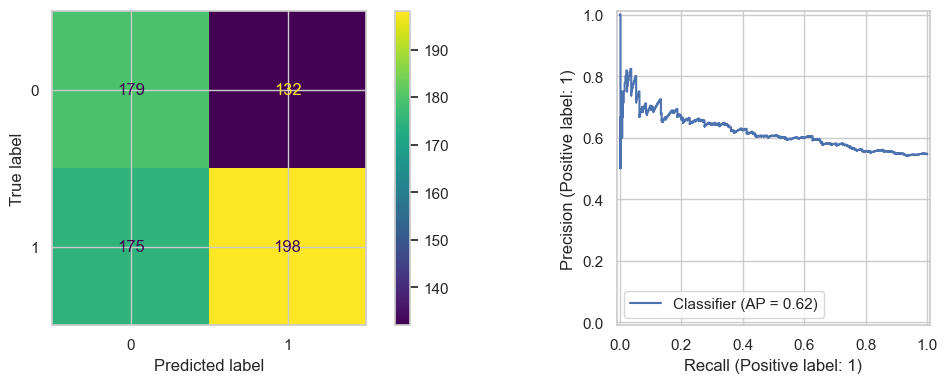

In [20]:
from sklearn.metrics import precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,brier_score_loss,classification_report,ConfusionMatrixDisplay,PrecisionRecallDisplay
pt=final.predict_proba(Xt)[:,1];yh=pt>=threshold
success_metrics={'average_precision':float(average_precision_score(yt,pt)),'ROC_AUC':float(roc_auc_score(yt,pt)),
 'Brier':float(brier_score_loss(yt,pt)),'precision':float(precision_score(yt,yh,zero_division=0)),
 'recall':float(recall_score(yt,yh,zero_division=0)),'F1':float(f1_score(yt,yh,zero_division=0)),
 'threshold':threshold,'test_n':len(yt),'test_prevalence':float(yt.mean()),'synthetic':True}
print(json.dumps(success_metrics,indent=2));print(classification_report(yt,yh,zero_division=0))
fig,ax=plt.subplots(1,2,figsize=(12,4));ConfusionMatrixDisplay.from_predictions(yt,yh,ax=ax[0]);PrecisionRecallDisplay.from_predictions(yt,pt,ax=ax[1]);plt.tight_layout();plt.show()

### 7.2 Reliability and calibration

Evaluate probability calibration on synthetic test data; reliability does not make the probabilities valid for real operations.

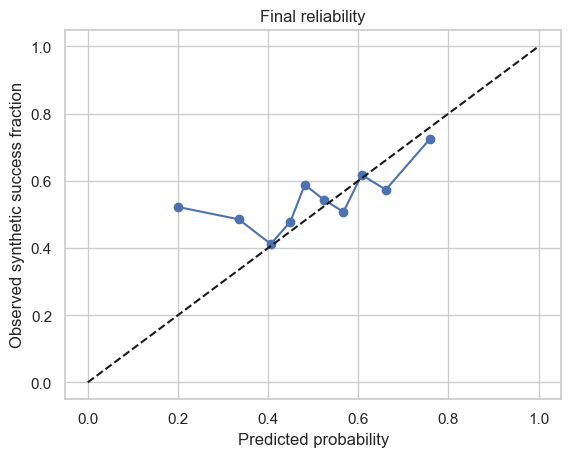

In [21]:
observed,predicted=calibration_curve(yt,pt,n_bins=10,strategy='quantile')
plt.plot(predicted,observed,'o-');plt.plot([0,1],[0,1],'k--');plt.xlabel('Predicted probability');plt.ylabel('Observed synthetic success fraction');plt.title('Final reliability');plt.show()

### 7.3 Performance by intervention type

Small subgroup counts and simulated assignment bias can make subgroup estimates unstable.

In [22]:
sub=[]
for kind,idx in test.groupby('intervention_type').groups.items():
    loc=test.index.get_indexer(idx);true=test.loc[idx,'target'];prob=pt[loc]
    sub.append({'intervention_type':kind,'n':len(true),'prevalence':true.mean(),'AP':average_precision_score(true,prob),'Brier':brier_score_loss(true,prob)})
subgroup=pd.DataFrame(sub);display(subgroup);subgroup.to_csv(OUT/'success_type_slices.csv',index=False)

,intervention_type,n,prevalence,AP,Brier
0,drain_clear,215,0.567442,0.669865,0.243070
1,pipe_repair,202,0.599010,0.658072,0.250406
2,pump_repair,151,0.523179,0.562804,0.296557
3,road_barrier,116,0.439655,0.508464,0.245192


## 08. Resolution-time estimation

Model positive observed time among completed synthetic jobs. The naive median and category median are training-only baselines. Compare Ridge and Random Forest regression with log1p target where suitable. Right-censoring is not modelled: incomplete items have unknown resolution duration and are excluded, so results apply only to completed records in this toy generator.

### 8.1 Build completed-time cohorts

Only completion status and recorded duration define eligibility. Completion time itself is not a feature.

In [23]:
completed=data[data.status.eq('completed') & data.resolution_hours.notna()].copy()
trd=completed[completed.period.eq('train')];vad=completed[completed.period.eq('validation')];ted=completed[completed.period.eq('test')]
assert trd.resolution_hours.gt(0).all()
duration_cat=['intervention_type','planned_crew_type'];duration_num=[c for c in FEATURES if c not in duration_cat]
prep_duration=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())]),duration_num),
 ('categorical',OneHotEncoder(handle_unknown='ignore'),duration_cat)])
def duration_pipeline(est):return Pipeline([('preprocess',__import__('sklearn.base',fromlist=['clone']).clone(prep_duration)),('model',est)])

### 8.2 Compare historical baseline and regressors

MAE/RMSE in hours describe synthetic completed work only.

In [24]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
regressors={'Ridge':duration_pipeline(Ridge(alpha=10)),
 'Random Forest':Pipeline([('preprocess',ColumnTransformer([('numeric',SimpleImputer(strategy='median',keep_empty_features=True),duration_num),('categorical',OneHotEncoder(handle_unknown='ignore'),duration_cat)])),('model',RandomForestRegressor(n_estimators=120,min_samples_leaf=8,max_depth=12,random_state=SEED,n_jobs=2))]),
 'XGBoost':Pipeline([('preprocess',ColumnTransformer([('numeric',SimpleImputer(strategy='median',keep_empty_features=True),duration_num),('categorical',OneHotEncoder(handle_unknown='ignore'),duration_cat)])),('model',XGBRegressor(n_estimators=120,max_depth=3,learning_rate=.05,objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=SEED))])}
Xdt=ted[FEATURES];ydt=ted.resolution_hours.to_numpy();rows=[]
for name,est in regressors.items():
    est.fit(trd[FEATURES],np.log1p(trd.resolution_hours));pred=np.maximum(0,np.expm1(est.predict(Xdt)))
    rows.append({'model':name,'MAE_hours':mean_absolute_error(ydt,pred),'RMSE_hours':mean_squared_error(ydt,pred)**.5})
base=float(trd.resolution_hours.median());rows.append({'model':'Train median baseline','MAE_hours':mean_absolute_error(ydt,np.repeat(base,len(ydt))),'RMSE_hours':mean_squared_error(ydt,np.repeat(base,len(ydt)))**.5})
duration_results=pd.DataFrame(rows);display(duration_results);duration_results.to_csv(OUT/'duration_comparison.csv',index=False)

,model,MAE_hours,RMSE_hours
0,Ridge,8.348561,13.953507
1,Random Forest,8.381921,14.110697
2,XGBoost,8.360199,14.056158
3,Train median baseline,9.978897,16.119642


### 8.3 Duration residual analysis

Long durations may remain difficult. Quantile spread and errors by type are descriptive.

Duration selection by validation MAE only {'Ridge': 8.20185409920916, 'Random Forest': 8.402102293334499, 'XGBoost': 8.27969086453056}


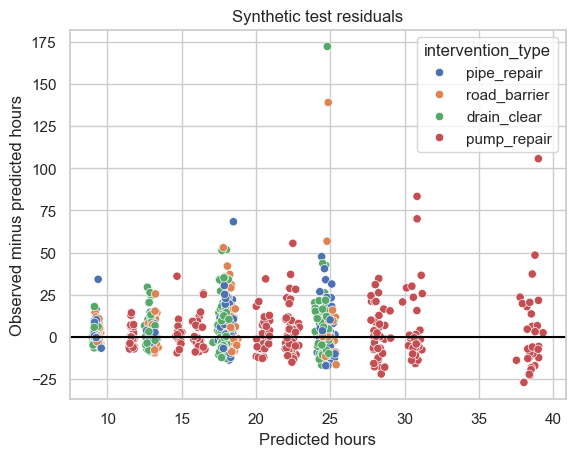

In [25]:
validation_duration={name:mean_absolute_error(vad.resolution_hours,np.maximum(0,np.expm1(est.predict(vad[FEATURES])))) for name,est in regressors.items()}
duration_best=min(validation_duration,key=validation_duration.get)
print('Duration selection by validation MAE only',validation_duration)
duration_model=regressors[duration_best]
duration_pred=np.maximum(0,np.expm1(duration_model.predict(Xdt)))
resid=ydt-duration_pred
sns.scatterplot(x=duration_pred,y=resid,hue=ted.intervention_type);plt.axhline(0,color='black');plt.xlabel('Predicted hours');plt.ylabel('Observed minus predicted hours');plt.title('Synthetic test residuals');plt.show()

## 09. Explainability, verification interface and export

Permutation importance uses validation data. The bundle accepts only known pre-intervention fields and emits synthetic-research warnings. Verification helpers reject work that is not completed, missing an independent verifier, or lacking evidence. Synthetic rows cannot be promoted to real verified labels.

### 9.1 Permutation importance

Importance reflects synthetic generator associations, not intervention mechanisms or causal effects.

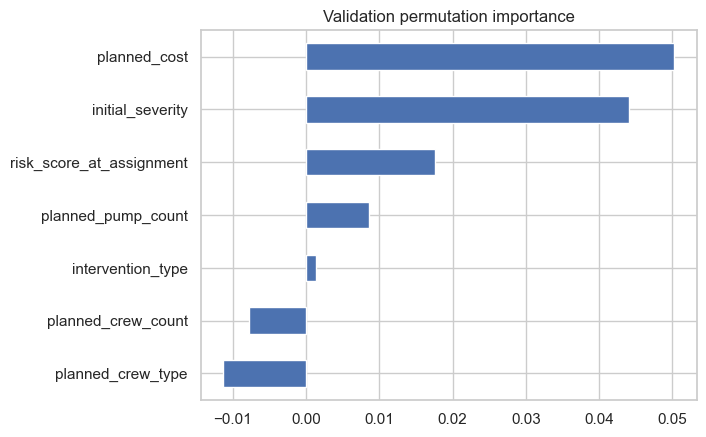

In [26]:
from sklearn.inspection import permutation_importance
imp=permutation_importance(final,val[FEATURES],val.target,scoring='average_precision',n_repeats=4,random_state=SEED,n_jobs=1)
importance=pd.Series(imp.importances_mean,index=FEATURES).sort_values()
importance.tail(15).plot.barh(title='Validation permutation importance');plt.show()
importance.to_csv(OUT/'success_permutation_importance.csv')

### 9.2 Validate completed versus verified distinction

A verified result cannot be created from an approved or in-progress work order.

In [27]:
unverified=data[data.outcome_status.eq('unverified')].iloc[0].to_dict()
try:verify_outcome(unverified,True,'reviewer-1','evidence://example')
except ValueError as error:print('Expected abstention:',error)
else:raise AssertionError('Unverified item incorrectly promoted')
completed_verified=data[data.outcome_status.str.startswith('verified_')].iloc[0].to_dict()
assert validate_outcome_record(completed_verified)['verified_by']

Expected abstention: Simulation outcomes cannot be promoted to real verified outcomes


### 9.3 Train bundle and validate prediction contract

The saved artifact is a synthetic surrogate. It cannot approve or dispatch an intervention.

In [28]:
chosen_duration=regressors[duration_best]
metadata={'component':'intervention_outcome_research','version':VERSION,'source_type':'synthetic','selected_success_model':selected,
 'selected_duration_model':duration_best,'features':FEATURES,'success_metrics':success_metrics,'duration_metric':duration_best,
 'synthetic_data_manifest':manifest,'causal_effect_estimate':None,'auto_approve':False,'dispatch_allowed':False,'duration_log1p':True,'success_supported':False,'operational_supported':False}
bundle=OutcomeBundle(final,chosen_duration,FEATURES,metadata)
joblib.dump(bundle,OUT/'pipeline.joblib')
example=leakage_safe_features(test.iloc[[0]])
pred=bundle.predict(test.iloc[0].to_dict());print(json.dumps(pred,indent=2))
assert pred['dispatch_allowed'] is False and pred['causal_effect'] is None
(OUT/'example_prediction.json').write_text(json.dumps(pred,indent=2))
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2,default=str))

{
  "component": "intervention_outcome_research",
  "version": "1.0.0",
  "source_type": "synthetic_research_surrogate",
  "status": "supported_research",
  "operational_supported": false,
  "allocation_eligible": false,
  "prediction_success_probability": null,
  "research_success_score": 0.7552607453404181,
  "predicted_resolution_hours": 9.256714546409432,
  "causal_effect": null,
  "requires_human_review": true,
  "auto_approve": false,
  "dispatch_allowed": false,
  "warnings": [
    "Synthetic records only; model does not estimate the causal benefit of an intervention.",
    "Do not use as a real success probability or approval decision."
  ]
}


1591

### 9.4 Artifact reload and inference schema

Reload the exact saved object and check stable prediction on a held-out example.

In [29]:
loaded=joblib.load(OUT/'pipeline.joblib')
reloaded=loaded.predict(test.iloc[0].to_dict())
for key,value in pred.items():
    if isinstance(value,float):assert np.isclose(reloaded[key],value,rtol=1e-12,atol=1e-12)
    else:assert reloaded[key]==value
(OUT/'feature_schema.json').write_text(json.dumps({'features':FEATURES,'excluded_post_intervention_fields':['completion_time','verification_time','verified_by','verified_success','outcome_status','resolution_hours']},indent=2))
(OUT/'success_metrics.json').write_text(json.dumps(success_metrics,indent=2))

302

### Findings and limitations

The notebook demonstrates a valid verification-aware schema and time-separated modelling workflow, but all fitted model metrics refer to synthetic outcomes. The simulation deliberately assigns resources based on severity, creating selection bias; logistic prediction does not estimate the intervention’s causal effect. Independent real intervention/completion/verification records, an established audit policy, representative resource histories and a clearly defined target population are prerequisites for real ML evaluation. Continue to use human approval and independently confirm outcomes.

## Targeted review — honest success baselines and simulation predictability

A low F1-selected cutoff can simply label everyone successful: its precision equals prevalence and its recall is one. Compare the classifier with a constant 0.5 score, the training success rate and per-intervention historical training rates. Also show the generator's latent success probability as an **oracle diagnostic only**, never as a fitted input or exported predictor. It bounds the mechanism's intrinsic predictability under this particular noisy simulation.

All post-intervention data remain outside predictors. The duration experiment is retained; its model is now chosen by validation MAE rather than test MAE. Its test period was already inspected previously, so these repaired results remain retrospective diagnostics. Uncompleted work is censored and excluded, so duration estimates apply only to the completed synthetic cohort.

,model,threshold,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Selected classifier,0.507379,0.600000,0.530831,0.563300,0.618917,0.570787,0.257404,0.424437,132,175,684,0.545322
1,Constant 0.5,0.500000,0.000000,0.000000,0.000000,0.545322,0.500000,0.250000,0.000000,0,373,684,0.545322
2,Training success rate,0.529549,0.000000,0.000000,0.000000,0.545322,0.500000,0.248195,0.000000,0,373,684,0.545322
3,Historical type rate,0.590909,0.582734,0.651475,0.615190,0.575832,0.545598,0.251189,0.559486,174,130,684,0.545322
4,Generator oracle (not deployable),0.622459,0.678392,0.361930,0.472028,0.648775,0.612782,0.238740,0.205788,64,238,684,0.545322


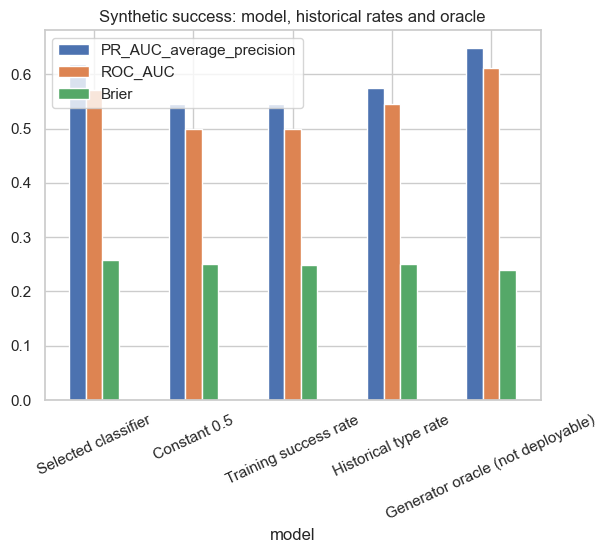

Threshold may change classification tradeoffs; it cannot improve ROC-AUC or average precision.
Success scores remain simulation diagnostics and are ineligible for resource allocation.


In [30]:
from src.civicflux.contracts import standardize
from src.civicflux.research import binary_metrics
prior=float(ytr.mean());rate=train.groupby('intervention_type').target.mean()
historical=val.intervention_type.map(rate).fillna(prior).to_numpy();historical_test=test.intervention_type.map(rate).fillna(prior).to_numpy()
baseline_scores={'Selected classifier':(pv,pt),'Constant 0.5':(np.repeat(.5,len(yv)),np.repeat(.5,len(yt))),
 'Training success rate':(np.repeat(prior,len(yv)),np.repeat(prior,len(yt))),'Historical type rate':(historical,historical_test),
 'Generator oracle (not deployable)':(val.latent_success_probability.to_numpy(),test.latent_success_probability.to_numpy())}
rows_success=[];saved=pd.DataFrame({'intervention_id':test.intervention_id,'assignment_time':test.assignment_time,'target':yt,'probability':pt})
for name,(vs,ts) in baseline_scores.items():
    t,_=select_score_threshold(yv,vs,objective='balanced_accuracy')
    rows_success.append({'model':name,'threshold':t,**binary_metrics(yt,ts,t)})
    saved[name]=ts
success_comparison=pd.DataFrame(rows_success);display(success_comparison)
success_comparison.to_csv(OUT/'success_baseline_comparison.csv',index=False);saved.to_csv(OUT/'test_predictions.csv',index=False)
success_comparison.plot.bar(x='model',y=['PR_AUC_average_precision','ROC_AUC','Brier'],rot=25,title='Synthetic success: model, historical rates and oracle');plt.show()
duration_saved=pd.DataFrame({'intervention_id':ted.intervention_id,'target':ydt,'prediction':duration_pred,'baseline':base})
duration_saved.to_csv(OUT/'duration_test_predictions.csv',index=False)
(OUT/'duration_validation.json').write_text(json.dumps(validation_duration,indent=2))
print('Threshold may change classification tradeoffs; it cannot improve ROC-AUC or average precision.')
print('Success scores remain simulation diagnostics and are ineligible for resource allocation.')
metadata.update(version='1.1.0',success_supported=False,operational_supported=False,success_threshold=threshold,
 duration_selection='validation MAE; completed synthetic cohort only')
bundle.metadata=metadata;joblib.dump(bundle,OUT/'pipeline.joblib');(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2,default=str))
standardize('intervention_outcomes',OUT,kind='synthetic success classifier + duration regressor',scope='synthetic intervention records only',
 units={'resolution':'hours','success_score':'unvalidated unitless simulation score'},horizon='post-completion synthetic outcome',
 provenance='seeded, confounded outcome generator; no real verification records',supported_inputs={'features':FEATURES,'out_of_scope':'real success estimates, causal effects and allocation'},
 validation='chronological synthetic holdout; unsupported success prediction, duration research only')
(OUT/'example_prediction.json').write_text(json.dumps(bundle.predict(test.iloc[0].to_dict()),indent=2))
assert bundle.predict(test.iloc[0].to_dict())['prediction_success_probability'] is None
assert bundle.predict(test.iloc[0].to_dict(),purpose='operational')['status']=='abstained'